In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import random
import seaborn as sns
import string
import textwrap
from collections import Counter
from copy import deepcopy
from datetime import timedelta
from time import time

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

DIR_DATA = "data"
DIR_HISTORIES = "histories"
DIR_MODELS = "models"

MODEL_RNN = "SimpleRNN"
MODEL_LSTM = "LSTM"
MODEL_GRU = "GRU"
MODEL_BILSTM = "BiLSTM"

sns.set_theme()
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

(current_device := torch.device("cuda" if torch.cuda.is_available() else "cpu"))

device(type='cuda')

# Разведочный анализ данных

**AG News Classification Dataset** — крупная коллекция новостных статей. Каждая статья относится к одной из четырёх тематик:

- *World* — мировые новости;
- *Sports* — спорт;
- *Business* — бизнес;
- *Sci/Tech* — наука и технологии.

Каждая запись включает *метку класса* (`Class Index`), *заголовок* (`Title`) и *краткое описание* (`Description`).

In [2]:
full_train_df = pd.read_csv(f"{DIR_DATA}/train.csv")
test_df = pd.read_csv(f"{DIR_DATA}/test.csv")

column_names = ["class_index", "title", "description"]
full_train_df.columns = column_names
test_df.columns = column_names

print(f"Размер обучающей выборки: {full_train_df.shape[0]}")
print(f"Размер тестовой выборки: {test_df.shape[0]}")

print("\nПримеры записей:")
full_train_df.sample(10, random_state=0)

Размер обучающей выборки: 120000
Размер тестовой выборки: 7600

Примеры записей:


,class_index,title,description
40739,4,First class to the moon,London - British airline magnate Richard Brans...
105532,4,Amazon #39;s Holiday Pi,Leave it to Amazon.com (Nasdaq: AMZN). Apparen...
45004,4,Will historic flight launch space tourism?,"Regardless, space competitions are poised to b..."
71894,1,Thais Drop Peace Bombs On Muslims,(CBS) Millions of folded paper cranes fluttere...
11970,3,U.S. Economy Grows at Slower Pace Than Expected,Struggling under the weight of a bloated trade...
9382,4,Space Radiation May Harm Astronauts' Blood Cells,In the time it takes you to read this sentence...
30582,1,US intelligence assessment on Iraq in line wit...,WASHINGTON -- A highly classified US intellige...
110897,3,Nikkei at 5-Week Closing Low,TOKYO (Reuters) - Japan's Nikkei stock averag...
64112,3,"LeapFrog Warns on 3Q, Year Profit View","LeapFrog Enterprises Inc., a developer of tech..."
77897,3,NTT DoCoMo Says Profit Declined 6 in First Half,NTT DoCoMo reported today that its profit fell...


In [3]:
print(
    "Пропуски в обучающей выборке:",
    full_train_df.isna().sum(),
    "\nПропуски в тестовой выборке:",
    test_df.isna().sum(),
    f"\nДубликатов в обучающей выборке: {full_train_df.duplicated().sum()}",
    f"Дубликатов в тестовой выборке: {test_df.duplicated().sum()}",
    sep="\n",
)

Пропуски в обучающей выборке:
class_index    0
title          0
description    0
dtype: int64

Пропуски в тестовой выборке:
class_index    0
title          0
description    0
dtype: int64

Дубликатов в обучающей выборке: 0
Дубликатов в тестовой выборке: 0


В наборе данных зафиксировано следующее соответствие:

| Class Index | Class Name |
|:-:|:-:|
| 1 | World |
| 2 | Sports |
| 3 | Business |
| 4 | Sci/Tech |

Добавим столбец с названием категории и посмотрим, сколько документов каждого класса в обеих выборках.

In [4]:
class_names = ["World", "Sports", "Business", "Sci/Tech"]
class_names_map = {i + 1: name for i, name in enumerate(class_names)}

full_train_df["category"] = full_train_df.class_index.map(class_names_map)
test_df["category"] = test_df.class_index.map(class_names_map)

(class_counts := pd.DataFrame({
    "train": full_train_df.category.value_counts().reindex(class_names),
    "test": test_df.category.value_counts().reindex(class_names),
}))

,train,test
category,,
World,30000,1900
Sports,30000,1900
Business,30000,1900
Sci/Tech,30000,1900


Посмотрим на **количество слов** в заголовках и описаниях в исходном виде — так, как они хранятся в CSV. Разобьём текст по пробелам «наивно», без удаления пунктуации и приведения к нижнему регистру. Также посчитаем **количество символов** — это даст представление о том, сколько «шумовых» символов присутствует в тексте.

In [5]:
def get_word_counts(texts):
    return pd.Series([len(t.split()) for t in texts])

def get_char_counts(texts):
    return pd.Series([len(t) for t in texts])

train_word_counts = pd.DataFrame({
    "train_title": get_word_counts(full_train_df.title),
    "train_description": get_word_counts(full_train_df.description),
})
test_word_counts = pd.DataFrame({
    "test_title": get_word_counts(test_df.title),
    "test_description": get_word_counts(test_df.description),
})
word_stats = pd.concat(
    [train_word_counts.describe(), test_word_counts.describe()], axis=1,
).round(2)

train_char_counts = pd.DataFrame({
    "train_title": get_char_counts(full_train_df.title),
    "train_description": get_char_counts(full_train_df.description),
})
test_char_counts = pd.DataFrame({
    "test_title": get_char_counts(test_df.title),
    "test_description": get_char_counts(test_df.description),
})
char_stats = pd.concat(
    [train_char_counts.describe(), test_char_counts.describe()], axis=1,
).round(2)

print("Количество слов в заголовках и описаниях:")
display(word_stats)
print("Количество символов в заголовках и описаниях:")
display(char_stats)

Количество слов в заголовках и описаниях:


,train_title,train_description,test_title,test_description
count,120000.00,120000.00,7600.00,7600.00
mean,6.78,31.06,6.76,30.96
std,2.09,9.76,2.11,9.80
min,1.00,1.00,1.00,4.00
25%,5.00,25.00,5.00,25.00
50%,7.00,30.00,7.00,30.00
75%,8.00,36.00,8.00,36.00
max,19.00,173.00,17.00,129.00


Количество символов в заголовках и описаниях:


,train_title,train_description,test_title,test_description
count,120000.00,120000.00,7600.00,7600.00
mean,42.07,193.39,41.88,192.41
std,13.57,64.47,13.48,63.19
min,6.00,6.00,6.00,37.00
25%,33.00,155.00,33.00,154.00
50%,41.00,188.00,41.00,187.00
75%,49.00,219.00,49.00,218.00
max,115.00,985.00,96.00,830.00


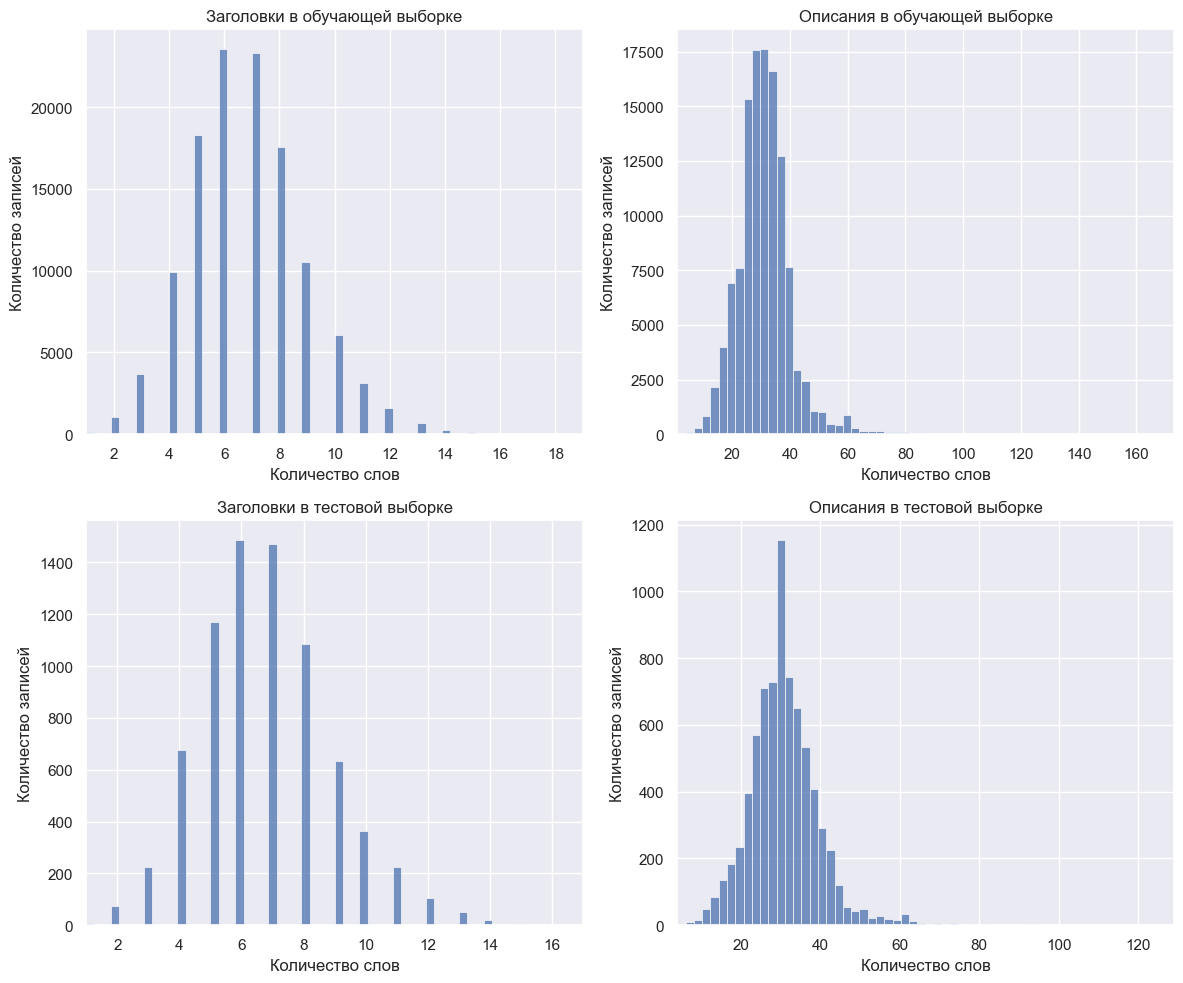

In [6]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten()

lengths_plot_titles = [
    "Заголовки в обучающей выборке", "Описания в обучающей выборке",
    "Заголовки в тестовой выборке", "Описания в тестовой выборке",
]

word_counts_series = [
    train_word_counts.train_title, train_word_counts.train_description,
    test_word_counts.test_title, test_word_counts.test_description,
]

for ax, series, title in zip(axes, word_counts_series, lengths_plot_titles):
    sns.histplot(series, bins=60, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Количество слов")
    ax.set_ylabel("Количество записей")
    ax.set_xlim(series.min(), series.max())

plt.tight_layout()

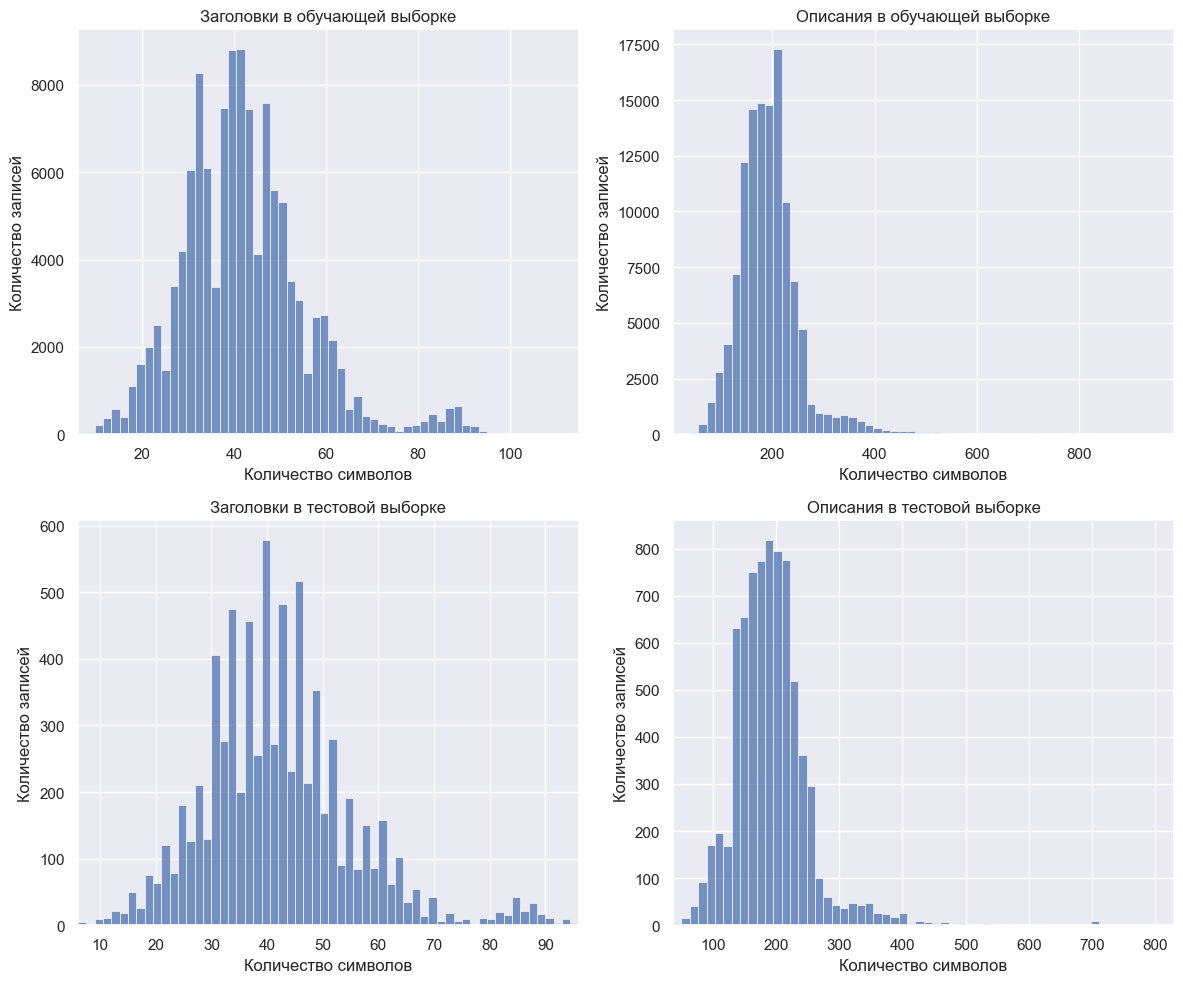

In [7]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten()

char_counts_series = [
    train_char_counts.train_title, train_char_counts.train_description,
    test_char_counts.test_title, test_char_counts.test_description,
]

for ax, series, title in zip(axes, char_counts_series, lengths_plot_titles):
    sns.histplot(series, bins=60, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Количество символов")
    ax.set_ylabel("Количество записей")
    ax.set_xlim(series.min(), series.max())

plt.tight_layout()

Объединим заголовки и описания.

In [8]:
full_train_df["text"] = (full_train_df.title + " " + full_train_df.description).str.strip()
test_df["text"] = (test_df.title + " " + test_df.description).str.strip()

print("Примеры объединённых текстов:")
sample_indices = full_train_df.sample(5, random_state=0).index.to_list()
with pd.option_context("display.max_colwidth", 120):
    display(full_train_df.text.iloc[sample_indices])

Примеры объединённых текстов:


40739     First class to the moon London - British airline magnate Richard Branson announced a plan on Monday for the world #3...
105532    Amazon #39;s Holiday Pi Leave it to Amazon.com (Nasdaq: AMZN). Apparently, the holiday season could be a rich opport...
45004                Will historic flight launch space tourism? Regardless, space competitions are poised to become big business.
71894     Thais Drop Peace Bombs On Muslims (CBS) Millions of folded paper cranes fluttered down from warplanes in the skies o...
11970     U.S. Economy Grows at Slower Pace Than Expected Struggling under the weight of a bloated trade deficit, the U.S. eco...
Name: text, dtype: object

Применим **токенизацию**: приведём к нижнему регистру, заменим пунктуацию пробелами, разобьём по пробелам.

In [9]:
punctuation_to_space = str.maketrans(
    string.punctuation, " " * len(string.punctuation)
)

def tokenize_texts(texts):
    tokens = []
    for text in texts:
        text = str(text).lower().translate(punctuation_to_space)
        tokens.append(text.split())
    return tokens

sample_tokens = tokenize_texts(full_train_df.text)
print("Примеры токенов, извлечённых из текстов:\n")
for sample_index in sample_indices:
    print(sample_tokens[sample_index])

Примеры токенов, извлечённых из текстов:

['first', 'class', 'to', 'the', 'moon', 'london', 'british', 'airline', 'magnate', 'richard', 'branson', 'announced', 'a', 'plan', 'on', 'monday', 'for', 'the', 'world', '39', 's', 'first', 'commercial', 'space', 'flights', 'saying', 'quot', 'thousands', 'quot', 'of', 'fee', 'paying', 'astronauts', 'could', 'be', 'sent', 'into', 'orbit', 'in', 'the', 'near', 'future']
['amazon', '39', 's', 'holiday', 'pi', 'leave', 'it', 'to', 'amazon', 'com', 'nasdaq', 'amzn', 'apparently', 'the', 'holiday', 'season', 'could', 'be', 'a', 'rich', 'opportunity', 'to', 'addict', 'more', 'users', 'to', 'amazon', '39', 's', 'a9']
['will', 'historic', 'flight', 'launch', 'space', 'tourism', 'regardless', 'space', 'competitions', 'are', 'poised', 'to', 'become', 'big', 'business']
['thais', 'drop', 'peace', 'bombs', 'on', 'muslims', 'cbs', 'millions', 'of', 'folded', 'paper', 'cranes', 'fluttered', 'down', 'from', 'warplanes', 'in', 'the', 'skies', 'over', 'southern'

Сравним длины после токенизации с изначальными длинами — так мы увидим, сколько токенов убирает удаление пунктуации.

In [10]:
tokens_word_counts = pd.Series([len(tokens) for tokens in sample_tokens])
tokens_char_counts = pd.Series([len("".join(tokens)) for tokens in sample_tokens])

tokens_stats = pd.concat(
    [tokens_word_counts.describe(), tokens_char_counts.describe()], axis=1,
).round(2)
tokens_stats.columns = ["words_count", "chars_count"]

print("Количество слов и символов в полученных токенах:")
display(tokens_stats)

Количество слов и символов в полученных токенах:


,words_count,chars_count
count,120000.00,120000.00
mean,39.66,191.42
std,11.44,52.71
min,4.00,12.00
25%,33.00,159.00
50%,39.00,188.00
75%,45.00,216.00
max,183.00,797.00


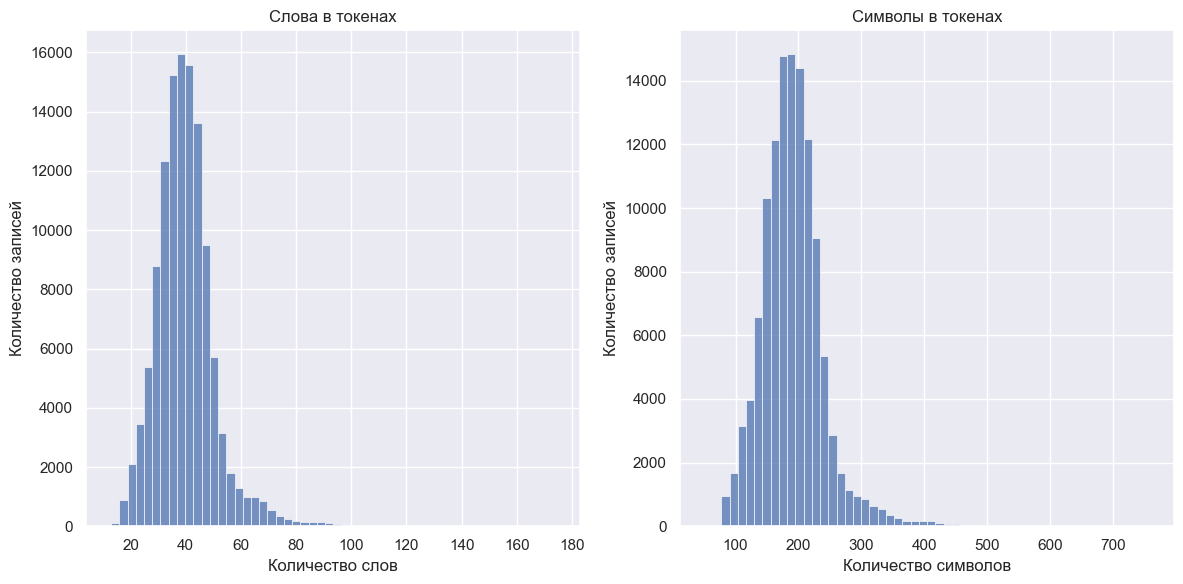

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))
axes = axes.flatten()

sns.histplot(tokens_word_counts, bins=60, ax=axes[0])
axes[0].set_title("Слова в токенах")
axes[0].set_xlabel("Количество слов")
axes[0].set_ylabel("Количество записей")
axes[0].set_xlim(tokens_word_counts.min(), tokens_word_counts.max())

sns.histplot(tokens_char_counts, bins=60, ax=axes[1])
axes[1].set_title("Символы в токенах")
axes[1].set_xlabel("Количество символов")
axes[1].set_ylabel("Количество записей")
axes[1].set_xlim(tokens_char_counts.min(), tokens_char_counts.max())

plt.tight_layout()

Выберем оптимальное значение параметра `MAX_LENGTH`.

In [12]:
word_quantiles = [0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999]
word_quantile_values = [int(tokens_word_counts.quantile(q)) for q in word_quantiles]
df_word_quantiles = pd.DataFrame({
    "quantile": word_quantiles,
    "words_count": word_quantile_values,
})
df_word_quantiles.set_index("quantile", inplace=True)

print("Квантили распределения слов в текстах:")
display(df_word_quantiles)

max_lengths = [64, 96, 128]
max_lengths_coverage = [f"{(tokens_word_counts <= m).mean():.2%}" for m in max_lengths]
df_max_lengths_coverage = pd.DataFrame({
    "max_length": max_lengths,
    "coverage": max_lengths_coverage,
})
df_max_lengths_coverage.set_index("max_length", inplace=True)

print("Покрытие при разных значениях MAX_LENGTH:")
display(df_max_lengths_coverage)

Квантили распределения слов в текстах:


,words_count
quantile,
0.500,39
0.750,45
0.900,51
0.950,58
0.990,78
0.995,89
0.999,129


Покрытие при разных значениях MAX_LENGTH:


,coverage
max_length,
64,96.81%
96,99.70%
128,99.90%


**Выводы по разведочному анализу**
- Набор данных сбалансирован: во всех четырёх классах по 30 000 обучающих и по 1 900 тестовых документов.
- Пропусков и дубликатов нет.
- Заголовки короткие (≈7 токенов), описания заметно длиннее (≈30 токенов) и дают основной вклад в длину объединённого текста.
- Токенизация удаляет пунктуацию и лишь немного уменьшает количество токенов относительно сырого разбиения по пробелам, т.е. потери смысла нет.
- Распределения длин в обучающей и тестовой выборках практически совпадают.
- По квантилям выбираем **`MAX_LENGTH = 128`**. Такое значение покрывает больше 99 % документов и обеспечивает разумную скорость обучения рекуррентных моделей.
- Словарь будем строить только по обучающей выборке — это будет сделано в следующем разделе.

# Подготовка данных для обучения

Разобьём исходную обучающую выборку на обучающую и валидационную в соотношении 90/10 со стратификацией по классам.

In [13]:
train_df, valid_df = train_test_split(
    full_train_df, test_size=0.1, stratify=full_train_df.category, random_state=0,
)
train_df.reset_index(drop=True, inplace=True)
valid_df.reset_index(drop=True, inplace=True)

print(f"Размер обучающей выборки: {train_df.shape[0]}")
print(f"Размер валидационной выборки: {valid_df.shape[0]}")
print(f"Размер тестовой выборки: {test_df.shape[0]}")

Размер обучающей выборки: 108000
Размер валидационной выборки: 12000
Размер тестовой выборки: 7600


In [14]:
(classes_distribution := pd.DataFrame({
    "train": train_df.category.value_counts().reindex(class_names),
    "valid": valid_df.category.value_counts().reindex(class_names),
    "test":  test_df.category.value_counts().reindex(class_names),
}))

,train,valid,test
category,,,
World,27000,3000,1900
Sports,27000,3000,1900
Business,27000,3000,1900
Sci/Tech,27000,3000,1900


In [15]:
train_tokens = tokenize_texts(train_df.text)
valid_tokens = tokenize_texts(valid_df.text)
test_tokens = tokenize_texts(test_df.text)

print(f"Пример токенизированного текста:\n{train_tokens[0]}")

Пример токенизированного текста:
['israel', 'europe', 'could', 'be', 'on', 'collision', 'course', 'report', 'reuters', 'reuters', 'israel', 'could', 'end', 'up', 'on', 'a', 'collision', 'course', 'with', 'the', 'european', 'union', 'and', 'face', 'sanctions', 'like', 'apartheid', 'era', 'south', 'africa', 'unless', 'the', 'israeli', 'palestinian', 'conflict', 'is', 'resolved', 'a', 'confidential', 'government', 'report', 'warns']


**Построение словаря**

Считаем частоты слов только по обучающей выборке. Ограничим словарь `VOCAB_SIZE = 20 000` наиболее частотными словами — это уменьшит размер эмбеддингов и ускорит обучение. Добавляем два служебных токена:
- `<PAD>` — дополнение коротких последовательностей (индекс 0);
- `<UNK>` — замена слов, отсутствующих в словаре (индекс 1).

In [16]:
VOCAB_SIZE = 20_000

word_counter = Counter()
for tokens in train_tokens:
    word_counter.update(tokens)

print(f"Количество уникальных слов в обучающей выборке: {len(word_counter)}")

pd.DataFrame(word_counter.most_common(20), columns=["Слово", "Частота"])

Количество уникальных слов в обучающей выборке: 62502


,Слово,Частота
0,the,184945
1,to,108717
2,a,101993
3,of,88839
4,in,86896
5,and,62782
6,s,55600
7,on,51934
8,for,45539
9,39,40015


In [17]:
most_common_words = word_counter.most_common(VOCAB_SIZE)

word2idx = {"<PAD>": 0, "<UNK>": 1}
word2idx.update({
    word: idx for idx, (word, _) in enumerate(most_common_words, start=2)
})
print(f"Итоговый размер словаря: {len(word2idx)}")

print(
    "Покрытие данных: "
    f"{sum(count for _, count in most_common_words) / sum(word_counter.values()):.2%}"
)

pd.DataFrame(list(word2idx.items())[:10], columns=["Токен", "Индекс"])

Итоговый размер словаря: 20002
Покрытие данных: 97.59%


,Токен,Индекс
0,<PAD>,0
1,<UNK>,1
2,the,2
3,to,3
4,a,4
5,of,5
6,in,6
7,and,7
8,s,8
9,on,9


Каждый документ превращаем в список числовых идентификаторов. Если токен отсутствует в словаре — используем индекс `<UNK>`.

In [18]:
def text_to_sequence(tokens):
    return [word2idx.get(token, word2idx["<UNK>"]) for token in tokens]

train_sequences = [text_to_sequence(t) for t in train_tokens]
valid_sequences = [text_to_sequence(t) for t in valid_tokens]
test_sequences = [text_to_sequence(t) for t in test_tokens]

print(
    "Пример соотношения токенов и их индексов:",
    train_tokens[0],
    train_sequences[0],
    sep="\n",
)

Пример соотношения токенов и их индексов:
['israel', 'europe', 'could', 'be', 'on', 'collision', 'course', 'report', 'reuters', 'reuters', 'israel', 'could', 'end', 'up', 'on', 'a', 'collision', 'course', 'with', 'the', 'european', 'union', 'and', 'face', 'sanctions', 'like', 'apartheid', 'era', 'south', 'africa', 'unless', 'the', 'israeli', 'palestinian', 'conflict', 'is', 'resolved', 'a', 'confidential', 'government', 'report', 'warns']
[429, 366, 95, 34, 9, 5773, 1215, 156, 22, 22, 429, 95, 146, 37, 9, 4, 5773, 1215, 13, 2, 169, 287, 7, 318, 1303, 303, 13532, 2122, 217, 735, 2458, 2, 324, 296, 1684, 17, 5587, 4, 9729, 97, 156, 1133]


Все последовательности приводим к длине `MAX_LENGTH = 128`: длинные обрезаем, короткие дополняем `<PAD>`.

In [19]:
MAX_LENGTH = 128

def pad_sequence(sequence, max_length=MAX_LENGTH, pad_value=0):
    sequence = sequence[:max_length]
    if len(sequence) < max_length:
        sequence = sequence + [pad_value] * (max_length - len(sequence))
    return sequence

train_padded = [pad_sequence(s) for s in train_sequences]
valid_padded = [pad_sequence(s) for s in valid_sequences]
test_padded = [pad_sequence(s) for s in test_sequences]

print(
    "Пример последовательности после паддинга:",
    train_padded[0],
    f"Получившаяся длина: {len(train_padded[0])}",
    sep="\n",
)

Пример последовательности после паддинга:
[429, 366, 95, 34, 9, 5773, 1215, 156, 22, 22, 429, 95, 146, 37, 9, 4, 5773, 1215, 13, 2, 169, 287, 7, 318, 1303, 303, 13532, 2122, 217, 735, 2458, 2, 324, 296, 1684, 17, 5587, 4, 9729, 97, 156, 1133, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Получившаяся длина: 128


Категории (`World`, `Sports`, `Business`, `Sci/Tech`) нужно заменить целочисленными кодами — так требует `CrossEntropyLoss`. Используем `LabelEncoder`, обученный на train, чтобы гарантировать одинаковый порядок классов.

In [20]:
label_encoder = LabelEncoder()
train_labels = label_encoder.fit_transform(train_df.category)
valid_labels = label_encoder.transform(valid_df.category)
test_labels = label_encoder.transform(test_df.category)

NUM_CLASSES = len(label_encoder.classes_)

pd.DataFrame({
    "Категория": label_encoder.classes_,
    "Код": label_encoder.transform(label_encoder.classes_),
})

,Категория,Код
0,Business,0
1,Sci/Tech,1
2,Sports,2
3,World,3


Преобразуем подготовленные данные в тензоры PyTorch и обернём в `TensorDataset`. Перемешиваем обучающую выборку, а валидационную и тестовую — нет.

In [21]:
BATCH_SIZE = 64

X_train = torch.tensor(train_padded, dtype=torch.long)
y_train = torch.tensor(train_labels, dtype=torch.long)
X_valid = torch.tensor(valid_padded, dtype=torch.long)
y_valid = torch.tensor(valid_labels, dtype=torch.long)
X_test = torch.tensor(test_padded, dtype=torch.long)
y_test = torch.tensor(test_labels, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
valid_dataset = TensorDataset(X_valid, y_valid)
test_dataset  = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(
    "Размерность данных для обучения:",
    f"X_train: {tuple(X_train.shape)}, y_train: {tuple(y_train.shape)}",
    f"X_valid: {tuple(X_valid.shape)}, y_valid: {tuple(y_valid.shape)}",
    f"X_test: {tuple(X_test.shape)}, y_test: {tuple(y_test.shape)}",
    sep="\n",
)

Размерность данных для обучения:
X_train: (108000, 128), y_train: (108000,)
X_valid: (12000, 128), y_valid: (12000,)
X_test: (7600, 128), y_test: (7600,)


In [22]:
X_batch, y_batch = next(iter(train_loader))

print(
    f"Форма батча текстов: {tuple(X_batch.shape)}",
    f"Форма батча меток: {tuple(y_batch.shape)}",
    f"\nПример последовательности из батча (первые 40 индексов):\n{X_batch[0][:40]}",
    f"\nМетка этого объекта: {y_batch[0].item()} ({label_encoder.classes_[y_batch[0].item()]})",
    sep="\n",
)

Форма батча текстов: (64, 128)
Форма батча меток: (64,)

Пример последовательности из батча (первые 40 индексов):
tensor([ 1846,  1211,   858,    35,  4601,  2152,    43,    46,    17,   858,
           10,  1222,     4,   380,     6,     2,  4601,  4131,    43,   126,
         3393,     1, 11614,   611,    22,     9,   120,  1456,   321,    15,
            2,    31,   259,     1,     0,     0,     0,     0,     0,     0])

Метка этого объекта: 3 (World)


Зафиксируем важные характеристики подготовленных данных, которые понадобятся при построении моделей:

| Параметр | Значение |
|---|---|
| VOCAB_SIZE | 20 000 + 2 служебных токена |
| MAX_LENGTH | 128 |
| NUM_CLASSES | 4 |
| BATCH_SIZE | 64 |

Данные полностью готовы к обучению моделей.

# Создание классов моделей

**Модель SimpleRNN**

Начнём с самой простой рекуррентной архитектуры — `nn.RNN`. Несмотря на то, что она уже практически не используется в реальных задачах, она служит удобной отправной точкой для сравнения: она недостаточно эффективно справляется с длинными зависимостями из-за проблемы затухающих градиентов, и последующие модели (LSTM, GRU) вводят те или иные улучшения, чтобы её решить.

Архитектура классификатора:

1. **Embedding** — преобразует индексы токенов в плотные векторы размерности `EMBEDDING_DIM`.
2. **SimpleRNN** — последовательно обрабатывает эмбеддинги и накапливает скрытое состояние.
3. **Linear** — использует финальное скрытое состояние для предсказания класса.

Параметр `padding_idx=word2idx["<PAD>"]` сообщает `Embedding`, что вектор `<PAD>` не должен обновляться при обучении — так `<PAD>`-токены на выходе не влияют на модель.

`nn.RNN` при `batch_first=True` возвращает:
- `output` формы `(batch, seq_len, hidden_dim)` — скрытые состояния для каждого шага;
- `hidden` формы `(num_layers, batch, hidden_dim)` — финальное скрытое состояние.

Для классификации берём `hidden[-1]` — состояние последнего слоя после последнего шага.

In [23]:
EMBEDDING_DIM = 128
HIDDEN_DIM = 128

class SimpleRNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, padding_idx=0):
        super().__init__()
        # Слой эмбеддингов: преобразует индексы токенов в плотные векторы
        # padding_idx=0 означает, что вектор <PAD> не обучается и остаётся нулевым
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )
        # Однонаправленный рекуррентный слой SimpleRNN
        # batch_first=True: вход и выход имеют форму (batch, seq_len, hidden_dim)
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )
        # Полносвязный слой-классификатор: hidden_dim → num_classes логитов
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # Вычисление реальных длин документов в батче (без учёта <PAD>)
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        # Прямой проход через слой эмбеддингов: (batch, seq_len) → (batch, seq_len, emb_dim)
        embedded = self.embedding(x)
        # Упаковка последовательностей, чтобы RNN обрабатывала только реальные токены
        # enforce_sorted=False избавляет от ручной сортировки батча по длинам
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        # Прямой проход через RNN; hidden[-1] — состояние на последнем реальном токене
        _, hidden = self.rnn(packed)
        # Классификация по финальному скрытому состоянию: (batch, hidden_dim) → (batch, num_classes)
        return self.classifier(hidden[-1])

**Модель LSTM**

**LSTM (Long Short-Term Memory)** — развитие классической RNN. Ключевое отличие: помимо скрытого состояния `h_t` LSTM поддерживает **cell state** `c_t` и три гейта — **input**, **forget** и **output**. Благодаря им:

- сеть может «запоминать» важную информацию на много шагов вперёд (гейт `forget` решает, что стирать из `cell state`, а `input` — что добавлять);
- градиенты текут через `cell state` почти без затухания, что решает проблему, характерную для SimpleRNN.

На уровне кода всё то же самое, что и у SimpleRNN, кроме одного: `nn.LSTM` возвращает кортеж `(hidden, cell)` — берём `hidden[-1]`.

In [24]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, padding_idx=0):
        super().__init__()
        # Слой эмбеддингов: индексы токенов → плотные векторы фиксированной размерности
        # padding_idx=0: вектор <PAD> не обучается и остаётся нулевым
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )
        # Однонаправленный LSTM-слой
        # batch_first=True: вход и выход имеют форму (batch, seq_len, hidden_dim)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )
        # Полносвязный классификатор: hidden_dim → num_classes логитов
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # Реальные длины документов в батче (без учёта <PAD>)
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        # Прямой проход через слой эмбеддингов
        embedded = self.embedding(x)
        # Упаковка последовательностей: LSTM обрабатывает только реальные токены
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        # LSTM возвращает кортеж (hidden, cell); нам нужно только hidden
        # hidden[-1] — состояние на последнем реальном токене
        _, (hidden, _) = self.lstm(packed)
        # Классификация по финальному скрытому состоянию
        return self.classifier(hidden[-1])

**Модель GRU**

**GRU (Gated Recurrent Unit)** — упрощённая альтернатива LSTM. У неё два гейта — **update** и **reset** — и нет отдельного **cell state**: вся «память» хранится в едином скрытом состоянии.

Практические последствия:

- GRU имеет **меньше параметров**, чем LSTM;
- обучение обычно **быстрее**;
- качество на многих задачах **сопоставимо** с LSTM или даже лучше.

По интерфейсу `nn.GRU` полностью аналогичен `nn.RNN`: возвращает `(output, hidden)`.

In [25]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, padding_idx=0):
        super().__init__()
        # Слой эмбеддингов: индексы токенов → плотные векторы
        # padding_idx=0: вектор <PAD> не обучается
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )
        # Однонаправленный GRU-слой
        # batch_first=True: вход и выход имеют форму (batch, seq_len, hidden_dim)
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )
        # Полносвязный классификатор
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # Реальные длины документов в батче (без учёта <PAD>)
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        # Прямой проход через слой эмбеддингов
        embedded = self.embedding(x)
        # Упаковка последовательностей: GRU обрабатывает только реальные токены
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        # GRU возвращает (output, hidden); нам нужно только hidden
        # hidden[-1] — состояние на последнем реальном токене
        _, hidden = self.gru(packed)
        # Классификация по финальному скрытому состоянию
        return self.classifier(hidden[-1])

**Модель BiLSTM**

**Bidirectional LSTM** — это два независимых LSTM-слоя, один из которых читает последовательность слева направо, а второй — справа налево. На выходе мы получаем **два** финальных скрытых состояния (по одному от каждого направления) и объединяем их конкатенацией.

Ключевые изменения по сравнению с обычной LSTM:

1. `bidirectional=True` в `nn.LSTM`;
2. **входной размер классификатора** теперь `2 * hidden_dim`, а не `hidden_dim`;
3. в `forward` берём **оба** финальных состояния: `hidden[-2]` (forward) и `hidden[-1]` (backward), объединяя их через `torch.cat(..., dim=1)`.

Такая архитектура лучше учитывает контекст: например, для слова в середине предложения она «видит» не только предшествующий текст, но и последующий. На задачах классификации текстов (где доступен весь документ целиком) это часто даёт заметный прирост качества.

In [26]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, padding_idx=0):
        super().__init__()
        # Слой эмбеддингов: индексы токенов → плотные векторы
        # padding_idx=0: вектор <PAD> не обучается
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )
        # Двунаправленный LSTM: две независимые рекуррентные сети в противоположных направлениях
        # batch_first=True: вход и выход имеют форму (batch, seq_len, hidden_dim)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True,
        )
        # Классификатор принимает конкатенацию состояний двух направлений (2 * hidden_dim)
        self.classifier = nn.Linear(2 * hidden_dim, num_classes)

    def forward(self, x):
        # Реальные длины документов в батче (без учёта <PAD>)
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        # Прямой проход через слой эмбеддингов
        embedded = self.embedding(x)
        # Упаковка последовательностей: BiLSTM обрабатывает только реальные токены
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        # hidden формы (2, batch, hidden_dim): hidden[-2] — forward, hidden[-1] — backward
        _, (hidden, _) = self.lstm(packed)
        # Конкатенация состояний двух направлений: (batch, hidden_dim) × 2 → (batch, 2 * hidden_dim)
        final_state = torch.cat([hidden[-2], hidden[-1]], dim=1)
        # Классификация по объединённому представлению
        return self.classifier(final_state)

# Создание вспомогательных функций для обучения

Будем использовать:
- функции `train_epoch`, `evaluate` и `predict` для обучения, валидации и тестирования модели;
- оптимизатор **Adam**;
- `ReduceLROnPlateau` для снижения LR, если `valid_acc` не растёт;
- **Early stopping** по `valid_acc`.

Функция `train_model` объединяет всё вместе:
- логирует `train_acc / train_loss / valid_acc / val_loss / lr` по эпохам;
- сохраняет лучшие веса на `valid_acc`;
- после обучения считает метрики на тесте и сохраняет модель в `models/`, а историю обучения в `histories/`.

In [27]:
class EarlyStopping:
    def __init__(self, patience, min_delta, mode):
        self.patience = patience  # количество эпох без улучшений, после которых нужна остановка
        self.min_delta = min_delta  # минимальное изменение, считающееся улучшением
        self.mode = mode  # "max" – чем больше, тем лучше; "min" – чем меньше, тем лучше
        self.counter = 0  # счётчик эпох без улучшений
        self.best_score = None  # лучшее значение метрики оценки качества
        self.early_stop = False  # флаг необходимости остановки
        self.best_model_state = None  # состояние лучшей модели
    
    def __call__(self, current_score, model):
        # Первый вызов
        if self.best_score is None:
            # Сохранение значения метрики
            self.best_score = current_score
            # Сохранение весов модели
            self.best_model_state = deepcopy(model.state_dict())

        # Проверка на отсутствие улучшения
        elif (self.mode == "max" and current_score < self.best_score + self.min_delta) or \
             (self.mode == "min" and current_score > self.best_score - self.min_delta):
            # Увеличение счётчика эпох без улучшений
            self.counter += 1
            # Если достигнуто задананное количество эпох без улучшений, то выполняется остановка
            if self.counter >= self.patience:
                self.early_stop = True
        
        # Фиксация улучшения
        else:
            # Сохранение лушчего значения метрики
            self.best_score = current_score
            # Сохранение лучших весов модели
            self.best_model_state = deepcopy(model.state_dict())
            # Обнуление счётчика эпоха без улучшений
            self.counter = 0

def train_epoch(model, loader, optimizer, criterion, device):
    # Переключение модели в режим обучения
    model.train()

    running_loss = 0.0  # суммарная ошибка
    correct = 0  # количество правильных ответов
    total = 0  # общее число обработанных примеров

    # Проход по батчам данных
    for inputs, targets in loader:
        # Перемещение тензоров на указанный CPU или GPU
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)

        # Обнуление градиентов перед вычислением градиентов нового батча
        optimizer.zero_grad()
        # Прямой проход: получение сырых предсказаний
        outputs = model(inputs)
        # Вычисление функции потерь
        loss = criterion(outputs, targets)
        # Обратный проход: вычисление градиентов функции потерь по всем параметрам модели
        loss.backward()
        # Обрезка нормы градиентов для предотвращения их взрыва
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        # Обновление весов модели
        optimizer.step()
        
        # Прибавление суммарных потерь для всех примеров батча
        running_loss += loss.item() * inputs.size(0)
        # Получение предсказанных классов
        _, predicted = torch.max(outputs, 1)
        # Прибавление количества обработанных примеров
        total += targets.size(0)
        # Прибавление количества верных ответов
        correct += (predicted == targets).sum().item()
    
    # Вычисление средних потерь за эпоху
    epoch_loss = running_loss / total
    # Вычисление точности за эпоху
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion, device):
    # Переключение модели в режим оценки
    model.eval()

    running_loss = 0.0  # суммарная ошибка
    correct = 0  # количество правильных ответов
    total = 0  # общее число обработанных примеров

    # Отключение автоматического вычисления градиентов
    with torch.no_grad():
        # Проход по батчам данных
        for inputs, targets in loader:
            # Перемещение тензоров на указанный CPU или GPU
            inputs, targets = inputs.to(device), targets.to(device)

            # Прямой проход: получение сырых предсказаний
            outputs = model(inputs)
            # Вычисление функции потерь
            loss = criterion(outputs, targets)

            # Прибавление суммарных потерь для всех примеров батча
            running_loss += loss.item() * inputs.size(0)
            # Получение предсказанных классов
            _, predicted = torch.max(outputs, 1)
            # Прибавление количества обработанных примеров
            total += targets.size(0)
            # Прибавление количества верных ответов
            correct += (predicted == targets).sum().item()
    
    # Вычисление средних потерь за эпоху
    epoch_loss = running_loss / total
    # Вычисление точности за эпоху
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc


def predict(model, loader, device):
    # Переключение модели в режим оценки
    model.eval()

    # Список для тензоров вероятностей
    all_probs = []

    # Отключение автоматического вычисления градиентов
    with torch.no_grad():
        # Проход по батчам данных
        for data, _ in loader:
            # Перемещение тензоров на указанный CPU или GPU
            data = data.to(device)
            
            # Прямой проход: получение сырых предсказаний (логитов)
            output = model(data)

            # Преобразование логитов в вероятности распределения по классам
            probs = torch.softmax(output, dim=1)

            # Перемещение тензоров с GPU на CPU при необходимости
            # и добавление в список тензора
            all_probs.append(probs.cpu())
    
    # Объединение списка тензоров в один массив
    return torch.cat(all_probs).numpy()

def save_history(history, model_name):
    path = os.path.join(DIR_HISTORIES, f"{model_name}.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(history, f, ensure_ascii=False, indent=2)
    return path

def load_history(model_name):
    path = os.path.join(DIR_HISTORIES, f"{model_name}.json")
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def train_model(
    model, model_name, train_loader, valid_loader, test_loader,
    n_epochs=20, learning_rate=1e-3, scheduler_factor=0.5, scheduler_patience=2,
    early_stopping_patience=3, early_stopping_min_delta=1e-3,
):
    model = model.to(current_device)
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Обучение модели {model_name}:")

    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer=optimizer,
        mode="max",
        factor=scheduler_factor,
        patience=scheduler_patience,
    )
    early_stopping = EarlyStopping(
        patience=early_stopping_patience,
        min_delta=early_stopping_min_delta,
        mode="max",
    )

    train_losses, train_accs, valid_losses, valid_accs = [], [], [], []
    start_time = time()
    
    for epoch in range(n_epochs):
        epoch_start_time = time()

        train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, current_device)
        valid_loss, valid_acc = evaluate(model, valid_loader, criterion, current_device)

        epoch_time = round(time() - epoch_start_time)

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        valid_losses.append(valid_loss)
        valid_accs.append(valid_acc)

        print(
            f"Epoch {epoch + 1:2d}/{n_epochs} ({epoch_time}s) - "
            f"train_acc: {train_acc:.4f} - train_loss: {train_loss:.4f} - "
            f"valid_acc: {valid_acc:.4f} - valid_loss: {valid_loss:.4f} - "
            f"lr: {round(optimizer.param_groups[0]['lr'], 6)}"
        )

        scheduler.step(valid_acc)
        early_stopping(valid_acc, model)
        if early_stopping.early_stop:
            print(f"Ранняя остановка на эпохе {epoch + 1}")
            break
    else:
        print(f"Обучение завершено на эпохе {epoch + 1}")

    elapsed_time = str(timedelta(seconds=round(time() - start_time)))

    model.load_state_dict(early_stopping.best_model_state)
    best_epoch = len(train_losses) - early_stopping.counter
    test_loss, test_acc = evaluate(model, test_loader, criterion, current_device)

    print(
        f"\nВремя обучения модели {model_name}: {elapsed_time} секунд",
        f"Лучшая точность на валидации: {early_stopping.best_score:.4f} (эпоха {best_epoch})",
        f"Точность на тестовой выборке: {test_acc:.4f}, потери: {test_loss:.4f}",
        sep="\n",
    )

    model_path = os.path.join(DIR_MODELS, f"{model_name}.pt")
    torch.save(model.state_dict(), model_path)
    print(f"\nМодель сохранена в '{model_path}'")

    history = {
        "model_name": model_name,
        "trainable_params": trainable_params,
        "train_losses": train_losses,
        "train_accs": train_accs,
        "valid_losses": valid_losses,
        "valid_accs": valid_accs,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "best_epoch": best_epoch,
        "elapsed_time": elapsed_time,
    }
    history_path = save_history(history, model_name)
    print(f"История обучения сохранена в '{history_path}'")
    
    model.to("cpu")
    torch.cuda.empty_cache()

# Обучение моделей

In [28]:
model_rnn = SimpleRNNClassifier(
    vocab_size=len(word2idx),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    padding_idx=word2idx["<PAD>"],
)

train_model(
    model=model_rnn,
    model_name=MODEL_RNN,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
)

Обучение модели SimpleRNN:
Epoch  1/20 (22s) - train_acc: 0.6776 - train_loss: 0.7834 - valid_acc: 0.8185 - valid_loss: 0.5411 - lr: 0.001
Epoch  2/20 (21s) - train_acc: 0.8443 - train_loss: 0.4819 - valid_acc: 0.8551 - valid_loss: 0.4606 - lr: 0.001
Epoch  3/20 (21s) - train_acc: 0.8758 - train_loss: 0.4039 - valid_acc: 0.8723 - valid_loss: 0.4177 - lr: 0.001
Epoch  4/20 (22s) - train_acc: 0.8942 - train_loss: 0.3518 - valid_acc: 0.8729 - valid_loss: 0.4213 - lr: 0.001
Epoch  5/20 (22s) - train_acc: 0.9048 - train_loss: 0.3186 - valid_acc: 0.8764 - valid_loss: 0.4049 - lr: 0.001
Epoch  6/20 (22s) - train_acc: 0.9139 - train_loss: 0.2892 - valid_acc: 0.8883 - valid_loss: 0.3863 - lr: 0.001
Epoch  7/20 (22s) - train_acc: 0.9221 - train_loss: 0.2597 - valid_acc: 0.8889 - valid_loss: 0.3759 - lr: 0.001
Epoch  8/20 (22s) - train_acc: 0.9291 - train_loss: 0.2369 - valid_acc: 0.8860 - valid_loss: 0.3843 - lr: 0.001
Epoch  9/20 (22s) - train_acc: 0.9363 - train_loss: 0.2149 - valid_acc: 0.892

In [29]:
model_lstm = LSTMClassifier(
    vocab_size=len(word2idx),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    padding_idx=word2idx["<PAD>"],
)

train_model(
    model=model_lstm,
    model_name=MODEL_LSTM,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
)

Обучение модели LSTM:
Epoch  1/20 (23s) - train_acc: 0.8110 - train_loss: 0.5139 - valid_acc: 0.8899 - valid_loss: 0.3360 - lr: 0.001
Epoch  2/20 (23s) - train_acc: 0.9115 - train_loss: 0.2723 - valid_acc: 0.9027 - valid_loss: 0.3009 - lr: 0.001
Epoch  3/20 (22s) - train_acc: 0.9333 - train_loss: 0.2053 - valid_acc: 0.9067 - valid_loss: 0.2943 - lr: 0.001
Epoch  4/20 (23s) - train_acc: 0.9490 - train_loss: 0.1555 - valid_acc: 0.9092 - valid_loss: 0.2966 - lr: 0.001
Epoch  5/20 (23s) - train_acc: 0.9615 - train_loss: 0.1159 - valid_acc: 0.9125 - valid_loss: 0.3098 - lr: 0.001
Epoch  6/20 (24s) - train_acc: 0.9725 - train_loss: 0.0838 - valid_acc: 0.9099 - valid_loss: 0.3441 - lr: 0.001
Epoch  7/20 (24s) - train_acc: 0.9801 - train_loss: 0.0598 - valid_acc: 0.9099 - valid_loss: 0.3951 - lr: 0.001
Epoch  8/20 (23s) - train_acc: 0.9855 - train_loss: 0.0434 - valid_acc: 0.9103 - valid_loss: 0.4155 - lr: 0.001
Ранняя остановка на эпохе 8

Время обучения модели LSTM: 0:03:05 секунд
Лучшая точ

In [30]:
model_gru = GRUClassifier(
    vocab_size=len(word2idx),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    padding_idx=word2idx["<PAD>"],
)

train_model(
    model=model_gru,
    model_name=MODEL_GRU,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
)

Обучение модели GRU:
Epoch  1/20 (23s) - train_acc: 0.8240 - train_loss: 0.4710 - valid_acc: 0.8979 - valid_loss: 0.3015 - lr: 0.001
Epoch  2/20 (23s) - train_acc: 0.9192 - train_loss: 0.2399 - valid_acc: 0.9101 - valid_loss: 0.2666 - lr: 0.001
Epoch  3/20 (23s) - train_acc: 0.9421 - train_loss: 0.1733 - valid_acc: 0.9132 - valid_loss: 0.2564 - lr: 0.001
Epoch  4/20 (23s) - train_acc: 0.9575 - train_loss: 0.1233 - valid_acc: 0.9138 - valid_loss: 0.2754 - lr: 0.001
Epoch  5/20 (22s) - train_acc: 0.9720 - train_loss: 0.0821 - valid_acc: 0.9099 - valid_loss: 0.3170 - lr: 0.001
Epoch  6/20 (23s) - train_acc: 0.9824 - train_loss: 0.0520 - valid_acc: 0.9093 - valid_loss: 0.3704 - lr: 0.001
Ранняя остановка на эпохе 6

Время обучения модели GRU: 0:02:17 секунд
Лучшая точность на валидации: 0.9132 (эпоха 3)
Точность на тестовой выборке: 0.9087, потери: 0.2710

Модель сохранена в 'models\GRU.pt'
История обучения сохранена в 'histories\GRU.json'


In [31]:
model_bilstm = BiLSTMClassifier(
    vocab_size=len(word2idx),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    padding_idx=word2idx["<PAD>"],
)

train_model(
    model=model_bilstm,
    model_name=MODEL_BILSTM,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
)

Обучение модели BiLSTM:
Epoch  1/20 (38s) - train_acc: 0.8345 - train_loss: 0.4538 - valid_acc: 0.8932 - valid_loss: 0.3114 - lr: 0.001
Epoch  2/20 (37s) - train_acc: 0.9199 - train_loss: 0.2355 - valid_acc: 0.9076 - valid_loss: 0.2783 - lr: 0.001
Epoch  3/20 (36s) - train_acc: 0.9444 - train_loss: 0.1642 - valid_acc: 0.9093 - valid_loss: 0.2717 - lr: 0.001
Epoch  4/20 (37s) - train_acc: 0.9628 - train_loss: 0.1080 - valid_acc: 0.9028 - valid_loss: 0.3309 - lr: 0.001
Epoch  5/20 (37s) - train_acc: 0.9774 - train_loss: 0.0663 - valid_acc: 0.9080 - valid_loss: 0.3491 - lr: 0.001
Epoch  6/20 (37s) - train_acc: 0.9875 - train_loss: 0.0385 - valid_acc: 0.9052 - valid_loss: 0.4035 - lr: 0.001
Ранняя остановка на эпохе 6

Время обучения модели BiLSTM: 0:03:42 секунд
Лучшая точность на валидации: 0.9093 (эпоха 3)
Точность на тестовой выборке: 0.9091, потери: 0.2715

Модель сохранена в 'models\BiLSTM.pt'
История обучения сохранена в 'histories\BiLSTM.json'


# Анализ динамики обучения

Загрузим сохранённые истории обучения всех четырёх моделей и построим единые графики потерь и точности. Так мы сможем проследить, как разные архитектуры сходятся, где выходят на плато и в какой момент начинает проявляться переобучение.

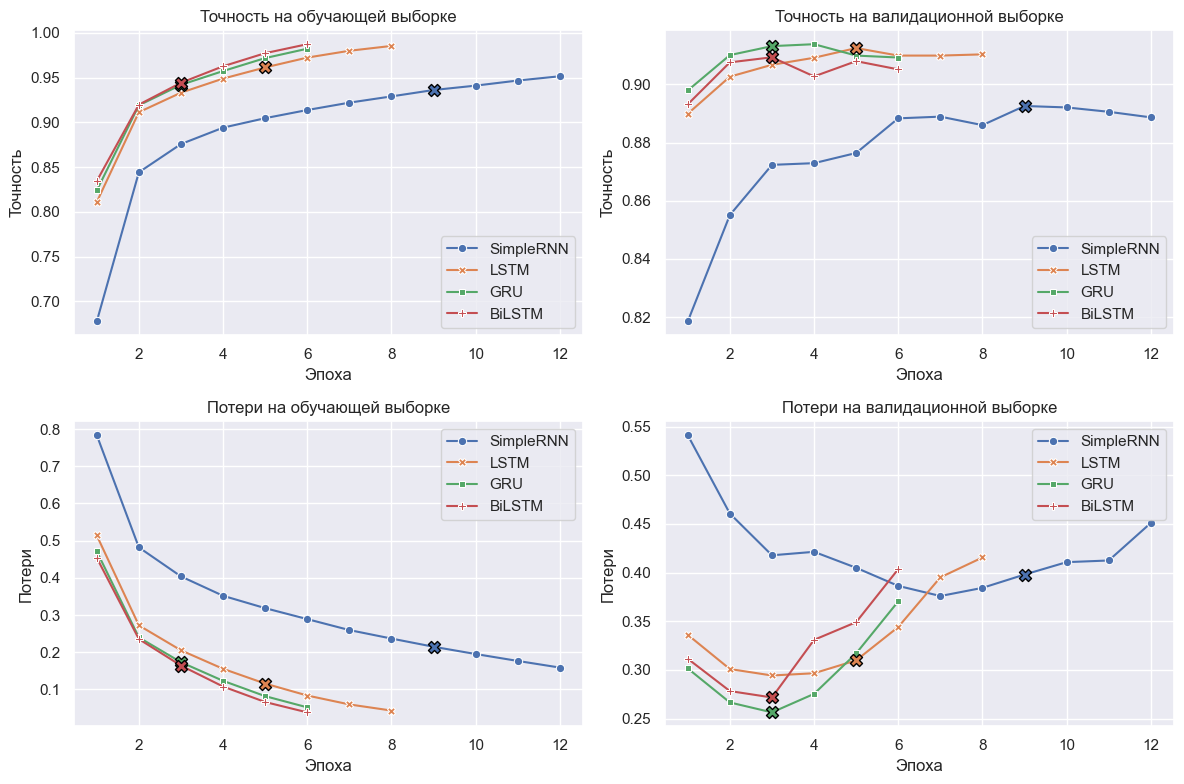

In [32]:
model_classes = {
    MODEL_RNN: SimpleRNNClassifier,
    MODEL_LSTM: LSTMClassifier,
    MODEL_GRU: GRUClassifier,
    MODEL_BILSTM: BiLSTMClassifier,
}

best_epochs = []
records_list = []

for model_name in model_classes:
    history = load_history(model_name)
    best_epoch = history["best_epoch"]

    best_epochs.append({
        "model": model_name,
        "best_epoch": best_epoch,
        "train_acc": history["train_accs"][best_epoch - 1],
        "valid_acc": history["valid_accs"][best_epoch - 1],
        "train_loss": history["train_losses"][best_epoch - 1],
        "valid_loss": history["valid_losses"][best_epoch - 1],
    })

    for epoch, (train_acc, valid_acc, train_loss, valid_loss) in enumerate(zip(
        history["train_accs"], history["valid_accs"],
        history["train_losses"], history["valid_losses"],
    )):
        records_list.append({
            "model": model_name,
            "epoch": epoch + 1,
            "train_acc": train_acc,
            "valid_acc": valid_acc,
            "train_loss": train_loss,
            "valid_loss": valid_loss,
        })

records_df = pd.DataFrame(records_list)

plot_params = {
    "y": ["train_acc", "valid_acc", "train_loss", "valid_loss"],
    "title": [
        "Точность на обучающей выборке",
        "Точность на валидационной выборке",
        "Потери на обучающей выборке",
        "Потери на валидационной выборке",
    ],
    "ylabel": ["Точность", "Потери"],
}

n_rows, n_cols = 2, 2
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(12, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    metric = plot_params["y"][i]

    sns.lineplot(
        data=records_df, x="epoch", y=metric, ax=ax,
        hue="model", style="model", dashes=False, markers=True,
    ).set(
        title=plot_params["title"][i],
        xlabel="Эпоха",
        xticks=range(0, 21, 2),
        ylabel=plot_params["ylabel"][i // 2],
    )

    for epoch_data, color in zip(best_epochs, sns.color_palette(n_colors=len(best_epochs))):
        ax.scatter(
            x=epoch_data["best_epoch"], y=epoch_data[metric],
            s=75, color=color, marker="X", edgecolor="black", zorder=5,
        )

    ax.legend(title="", loc="lower right" if i < 2 else "upper right")

plt.tight_layout()

**Наблюдения по динамике обучения**

- **SimpleRNN** сходится медленнее остальных и раньше выходит на плато. Кривые `valid_loss` и `valid_acc` у неё заметно «шумнее» — классический симптом того, что сеть плохо удерживает дальние зависимости и «цепляется» за локальные признаки. Разница `train_acc − valid_acc` у неё наименьшая: модель не столько переобучается, сколько недоучивается — её ёмкости не хватает, чтобы выучить более сложные закономерности.

- **LSTM**, **GRU** и **BiLSTM** демонстрируют более быструю сходимость: `valid_acc` у каждой из них становится больше `0.9` уже на 2-й эпохе. При этом `train_acc` у них уверенно уходит за `0.95`, а `valid_acc` замедляется — начинается переобучение, и `EarlyStopping` корректно откатывает модель к лучшей эпохе.

- **LSTM** сходится немного дольше, чем **GRU** и **BiLSTM**, притом графики `valid_loss` и `valid_acc` у неё стабильнее.

# Оценка качества лучшей модели

Определим модель с наибольшей точностью на тестовой выборке, загрузим её сохранённые веса и проанализируем:
- метрики precision / recall / f1 по каждому классу;
- матрицу ошибок (confusion matrix);
- несколько примеров ошибочной классификации.

In [33]:
best_model_name = max(
    model_classes, key=lambda name: load_history(name)["test_acc"],
)

best_history = load_history(best_model_name)
best_epoch = best_history["best_epoch"]
best_train_acc = best_history["train_accs"][best_epoch - 1]
best_valid_acc = best_history["valid_accs"][best_epoch - 1]

print(
    f"Лучшая модель: {best_model_name}",
    f"- точность на обучающей выборке: {best_train_acc:.4f} (эпоха {best_epoch})",
    f"- точность на валидационной выборке: {best_valid_acc:.4f} (эпоха {best_epoch})",
    f"- точность на тестовой выборке: {best_history['test_acc']:.4f}",
    sep="\n",
)

best_model = model_classes[best_model_name](
    vocab_size=len(word2idx),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    padding_idx=word2idx["<PAD>"],
).to(current_device)

best_model.load_state_dict(
    torch.load(os.path.join(DIR_MODELS, f"{best_model_name}.pt"), map_location=current_device)
)
best_model.eval()

Лучшая модель: LSTM
- точность на обучающей выборке: 0.9615 (эпоха 5)
- точность на валидационной выборке: 0.9125 (эпоха 5)
- точность на тестовой выборке: 0.9112


LSTMClassifier(
  (embedding): Embedding(20002, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (classifier): Linear(in_features=128, out_features=4, bias=True)
)

Подробнее рассмотрим предсказания лучшей модели на тестовой выборке.

In [34]:
y_true = y_test.numpy()
y_pred_proba = predict(best_model, test_loader, current_device)
y_pred = np.argmax(y_pred_proba, axis=1)

print(
    f"Текстов в тестовой выборке: {len(y_true)}",
    f"- верно классифицировано: {(y_true == y_pred).sum()}",
    f"- ошибочно классифицировано: {(y_true != y_pred).sum()}",
    sep="\n",
)

Текстов в тестовой выборке: 7600
- верно классифицировано: 6925
- ошибочно классифицировано: 675


Проанализируем `classification_report` лучшей модели на тестовой выборке.

In [35]:
print(classification_report(
    y_true, y_pred, target_names=label_encoder.classes_, digits=4,
))

              precision    recall  f1-score   support

    Business     0.8910    0.8774    0.8841      1900
    Sci/Tech     0.8824    0.8889    0.8857      1900
      Sports     0.9380    0.9800    0.9586      1900
       World     0.9328    0.8984    0.9153      1900

    accuracy                         0.9112      7600
   macro avg     0.9111    0.9112    0.9109      7600
weighted avg     0.9111    0.9112    0.9109      7600



Построим матрицу спутанности для лучшей модели.

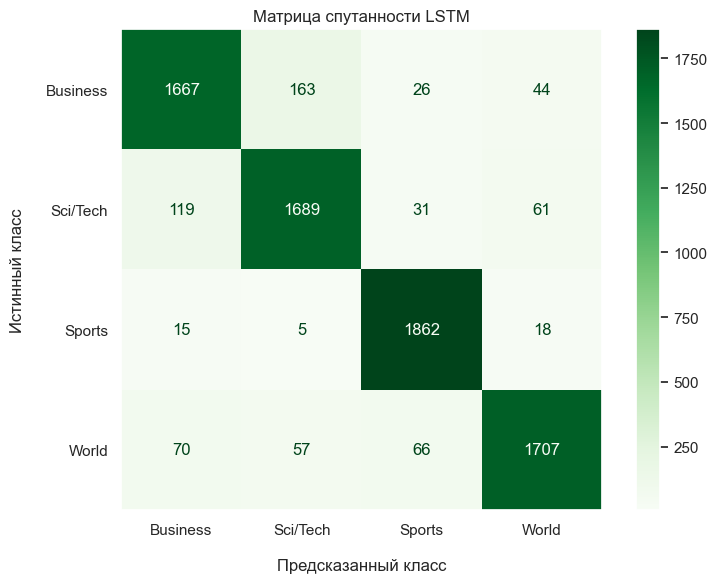

In [36]:
_, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true=y_true, y_pred=y_pred, cmap="Greens", ax=ax,
    display_labels=label_encoder.classes_,
)
ax.set_title(f"Матрица спутанности {best_model_name}")
ax.set_xlabel("Предсказанный класс", labelpad=15)
ax.set_ylabel("Истинный класс", labelpad=15)
ax.grid(False)
plt.tight_layout()

**Анализ ошибочной классификации**

- **Спортивные тексты** (Sports) отделяются от остальных новостей лучше всего. `recall` у данного класса значительно выше других. Спортивная лексика (названия команд, счёт, «match», «cup», «coach») очень характерна, и моделям тяжело её перепутать с чем-то другим.

- **Бизнес** (Business) и **наука и технологии** (Sci/Tech) — самая частая ситуация путаницы. В обеих категориях часто обсуждаются инновационные решения, стартапы, инвестиции, выпуски продуктов, так что такие тексты могут быть отнесены как к бизнесу, так и к технологиям.

- **Мировые новости** (World) также не редко путаются с остальными категориями. В мировых новостях часто обсуждаются экономические сюжеты, а в бизнес-новостях — политические решения (санкции, регулирование). Модель, у которой нет внешних знаний о мире, различает их в основном по лексическим маркерам, а они частично пересекаются.

Рассмотрим несколько примеров ошибочной классификации.

In [37]:
mistakes = np.where(y_true != y_pred)[0]
random.seed(0)
for i in random.sample(list(mistakes), 5):
    print(
        f"Истинный класс: {label_encoder.classes_[y_true[i]]}",
        f"Предсказание: {label_encoder.classes_[y_pred[i]]}",
        f"Уверенность: {y_pred_proba[i][y_pred[i]]:.4f}",
        f"\n{textwrap.fill(test_df.iloc[i]["text"], width=100)}\n",
        "-" * 100 + "\n",
        sep="\n",
    )

Истинный класс: Business
Предсказание: Sci/Tech
Уверенность: 0.8645

Web-based kidney match raises ethics questions A Colorado man who placed a  quot;transplant wanted
quot; ad on a Massachusetts-based Internet site is expected today to receive a kidney donated by a
total stranger who simply wanted to do  quot;something big. quot; The transaction marks the first
time an organ transplant has been brokered by a commercial web company.

----------------------------------------------------------------------------------------------------

Истинный класс: Sports
Предсказание: World
Уверенность: 0.8486

Paterno #39;s real tragedy may be not knowing when to go Joe Paterno often has talked about the
profound impact that a piece of classic literature has had on his life. While a student at Brooklyn
Prep in the early 1940s, he devoured TheAeneid, written by the Roman poet Virgil.

----------------------------------------------------------------------------------------------------

Истинный класс:

**Разбор ошибок в конкретных примерах**

1. **Business → Sci/Tech.** Текст лексически насыщен IT-словарём (*web-based*, *Internet site*, *commercial web company*), и модель цепляется за эти маркеры. Экономическая суть — коммерческое посредничество при трансплантации — выражена единственной фразой и теряется на фоне технического контекста.

2. **Sports → World.** В процитированном фрагменте спортивного контекста почти нет: имя «Патерно» в заголовке, а дальше — Вергилий, «Энеида», Бруклинская школа 1940-х. Это словарь из класса `World`. Модель не знает, что Джо Патерно — легендарный тренер по американскому футболу, поэтому выбирает по формальным лексическим признакам.

3. **Business → Sci/Tech.** Формально это типичная бизнес-новость (трудовой конфликт, увольнения), но модель видит *miners*, *diamond mining firm* и уводит документ в `Sci/Tech`. Дополнительный фактор — очень короткий текст (около 20 слов): у модели нет контекста, чтобы «взвесить» бизнес-сигналы против технических.

4. **World → Business.** Пограничный случай самой разметки: макроэкономика, Всемирный банк, статистика доходов — типичный бизнес-словарь, но новость помечена как `World`. Уверенность 0.97 отражает, что модель видит однозначные лексические маркеры и не сомневается. Для человека разметка здесь тоже спорна.

5. **Sci/Tech → World.** Криминальная лексика (*attacking*, *police officers*, *shot and killed*) доминирует, и модель уверенно относит текст к `World`. Настоящий контекст — обзор видеоигры — восстанавливается только из первой фразы и финального вопроса. Пример показывает, что модель может быть «уверенно неправа», и одной accuracy для оценки качества недостаточно.

По конкретным примерам ошибок видно, что модель опирается на **лексические сигналы** — она «цепляется» за отдельные слова (имена собственные, отраслевые термины), но иногда не учитывает общий контекст, который и определяет тематику статьи. Это ограничение самой архитектуры: даже LSTM «читает» текст один раз, **последовательно**, и у неё нет механизма явно посмотреть на разные части документа одновременно (это уже задача трансформеров).

# Итоговое сравнение архитектур

Сведём итоговые результаты всех четырёх моделей в одну таблицу, после чего сделаем выводы о том, какие ограничения решает каждая архитектура и когда её применение оправдано.

In [38]:
results_list = []

for model_name in model_classes:
    history = load_history(model_name)
    best_epoch = history["best_epoch"]

    results_list.append({
        "model": model_name,
        "params": history["trainable_params"],
        "time": history["elapsed_time"],
        "epochs": len(history["train_accs"]),
        "best_epoch": best_epoch,
        "train_acc": f"{history["train_accs"][best_epoch - 1]:.4f}",
        "train_loss": f"{history["train_losses"][best_epoch - 1]:.4f}",
        "valid_acc": f"{history["valid_accs"][best_epoch - 1]:.4f}",
        "valid_loss": f"{history["valid_losses"][best_epoch - 1]:.4f}",
        "test_acc": f"{history["test_acc"]:.4f}",
        "test_loss": f"{history["test_loss"]:.4f}",
    })

results_df = pd.DataFrame(results_list)
results_df.style.hide(axis="index")

model,params,time,epochs,best_epoch,train_acc,train_loss,valid_acc,valid_loss,test_acc,test_loss
SimpleRNN,2593796,0:04:21,12,9,0.9363,0.2149,0.8926,0.3979,0.8879,0.4022
LSTM,2692868,0:03:05,8,5,0.9615,0.1159,0.9125,0.3098,0.9112,0.3081
GRU,2659844,0:02:17,6,3,0.9421,0.1733,0.9132,0.2564,0.9087,0.2710
BiLSTM,2825476,0:03:42,6,3,0.9444,0.1642,0.9093,0.2717,0.9091,0.2715


Сравним количество ошибок всех моделей по классам на тестовой выборке.

In [39]:
error_masks = []
errors = []

for model_name in model_classes:
    model = model_classes[model_name](
        vocab_size=len(word2idx),
        embedding_dim=EMBEDDING_DIM,
        hidden_dim=HIDDEN_DIM,
        num_classes=NUM_CLASSES,
        padding_idx=word2idx["<PAD>"],
    ).to(current_device)

    model.load_state_dict(
        torch.load(os.path.join(DIR_MODELS, f"{model_name}.pt"), map_location=current_device)
    )
    model.eval()

    y_pred_model = np.argmax(predict(model, test_loader, current_device), axis=1)
    mask = (y_pred_model != y_true)
    error_masks.append(mask)

    n_errors = int(mask.sum())
    n_errors_by_class = np.bincount(y_true[mask], minlength=NUM_CLASSES)

    errors.append([model_name] + n_errors_by_class.tolist() + [n_errors])

    model.to("cpu")
    torch.cuda.empty_cache()

errors_df = pd.DataFrame(
    errors, columns=["Модель"] + list(label_encoder.classes_) + ["Всего ошибок"],
)
errors_df.style.hide(axis="index")

Модель,Business,Sci/Tech,Sports,World,Всего ошибок
SimpleRNN,266,268,71,247,852
LSTM,233,211,38,193,675
GRU,239,212,41,202,694
BiLSTM,247,184,83,177,691


**Выводы по архитектурам**

- **SimpleRNN** — базовая рекуррентная сеть без гейтов. Страдает от **затухающих градиентов**: информация из начала документа теряется к его концу. Применять её имеет смысл только как учебный пример или для очень коротких последовательностей (≤ 10 токенов), где проблема затухания не успевает проявиться.

- **LSTM** добавляет `cell state` и три гейта (`input`, `forget`, `output`), которые управляют тем, что запоминать, что забывать и что отдавать на выход. Градиенты текут через `cell state` почти без затухания, поэтому сеть реально **запоминает дальние зависимости** — это и даёт заметный скачок качества по сравнению с SimpleRNN. LSTM оправдана, когда качество критично и есть достаточно данных, чтобы модель не переобучалась; хорошо работает в задачах с длинными зависимостями (длинные документы, временные ряды).

- **GRU** — это «упрощённая LSTM» с двумя гейтами (`update` и `reset`) и без отдельного `cell state`. По качеству обычно сопоставима с LSTM, но имеет **меньше параметров** и часто обучается **быстрее**. На практике выбор между GRU и LSTM решается эмпирически, но для небольших и средних задач GRU нередко оказывается оптимальной по соотношению «качество / стоимость» — это хороший выбор для быстрого прототипа или деплоя на слабое железо.

- **BiLSTM** обрабатывает последовательность в двух направлениях и объединяет состояния `forward` и `backward`, благодаря чему каждое слово получает контекст не только слева, но и справа. На коротких текстах и ограниченных данных преимущество двунаправленности нивелируется склонностью к переобучению (параметров больше, а информации в коротких текстах не хватает), поэтому на нашем наборе она не отрывается от обычной LSTM. Зато BiLSTM отлично раскрывается на длинных документах и больших корпусах. Важное ограничение: она требует **полного доступа ко всему тексту целиком**, поэтому неприменима для онлайн-задач (стриминг, генерация по одному токену).